# Backend API benchmarks

Reads the newest file in backend/.benchmarks (from pytest tests/test_benchmark.py).

Run in backend folder:

`PYTHONPATH=. python -m pytest tests/test_benchmark.py --benchmark-only --benchmark-autosave`

In [29]:
#    PYTHONPATH=. python -m pytest tests/test_benchmark.py --benchmark-only --benchmark-autosave

import json
from pathlib import Path

import matplotlib.pyplot as plt

ORANGE = "#FF3E00"
BLACK = "#111111"

bench_dir = Path("backend") / ".benchmarks"
files = list(bench_dir.glob("*/*.json"))

if not files:
    raise FileNotFoundError("No benchmark json. Run pytest with --benchmark-autosave.")

path = max(files, key=lambda p: p.stat().st_mtime)
data = json.loads(path.read_text())

rows = []
for item in data["benchmarks"]:
    name = item["name"].replace("test_bench_", "")
    stats = item["stats"]
    extra = item.get("extra_info") or {}

    rows.append({
        "name": name,
        "mean_ms": stats["mean"] * 1000,
        "median_ms": stats["median"] * 1000,
        "sql_n": extra.get("sql_queries", 0),
    })

rows.sort(key=lambda r: r["mean_ms"])

print(path)
print()
for r in rows:
    print(f"{r['name']:26} mean {r['mean_ms']:.2f} ms  median {r['median_ms']:.2f} ms  sql {r['sql_n']}")

backend/.benchmarks/Linux-CPython-3.14-64bit/0005_1c809df4119dffa7163ed86ca70e33bbefe67579_20261101_184416_uncommitted-changes.json

get_meeting_empty          mean 1.12 ms  median 0.99 ms  sql 186
post_create_meeting        mean 3.46 ms  median 3.43 ms  sql 79
put_availability_small     mean 4.54 ms  median 4.47 ms  sql 523
get_meeting_loaded         mean 4.70 ms  median 4.13 ms  sql 343
put_availability_large     mean 7.88 ms  median 7.19 ms  sql 698


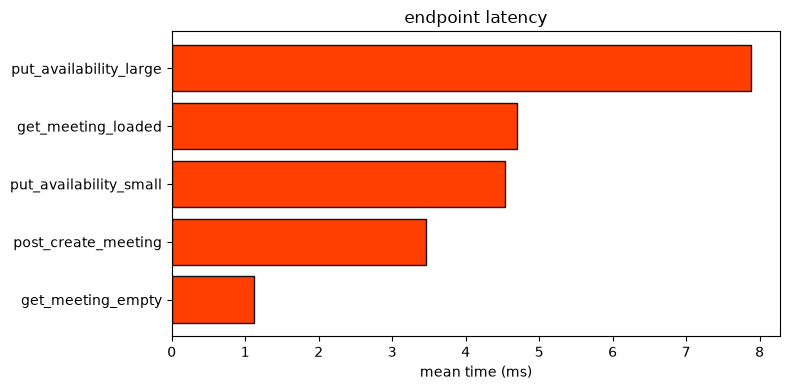

In [30]:
names = [r["name"] for r in rows]
means = [r["mean_ms"] for r in rows]

plt.figure(figsize=(8, 4))
plt.barh(names, means, color=ORANGE, edgecolor=BLACK)
plt.xlabel("mean time (ms)")
plt.title("endpoint latency")
plt.tight_layout()
plt.show()

**Plot 1 — endpoint latency (mean ms)**

Horizontal bars show average wall-clock time for one HTTP call (Flask test client, SQLite bench DB). **Shorter bar = faster.** Rows are sorted fastest at the top.

- **GET** on an empty meeting is usually the cheapest read.
- **PUT availability** with many slots tends to be slowest — each save rewrites slot rows in the database.

Use this chart when explaining *what the user waits on* per action, not total server load under many users.

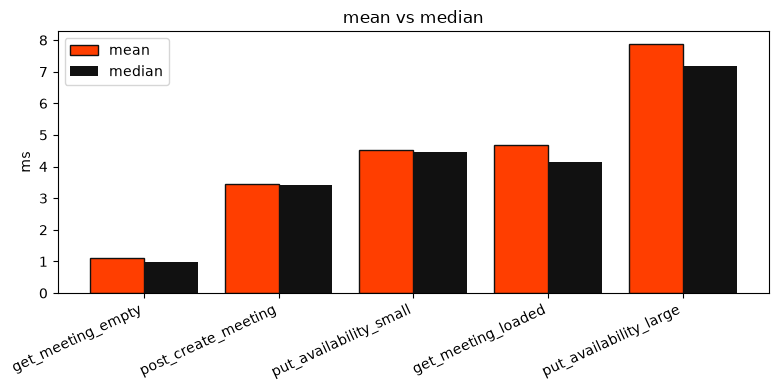

In [31]:
medians = [r["median_ms"] for r in rows]
x = range(len(names))

plt.figure(figsize=(8, 4))
plt.bar([i - 0.2 for i in x], means, 0.4, label="mean", color=ORANGE, edgecolor=BLACK)
plt.bar([i + 0.2 for i in x], medians, 0.4, label="median", color=BLACK)
plt.xticks(list(x), names, rotation=25, ha="right")
plt.ylabel("ms")
plt.legend()
plt.title("mean vs median")
plt.tight_layout()
plt.show()

**Plot 2 — mean vs median**

Same endpoints, two statistics from 30 benchmark rounds each.

- **Median (black):** typical run — good for “steady” performance.
- **Mean (orange):** pulled up by occasional slow runs (GC, cold cache, SQLite jitter).

If the orange bar is clearly taller than black for one endpoint (often **get_meeting_loaded**), mention variance in a report; do not treat a single mean as a hard SLA.

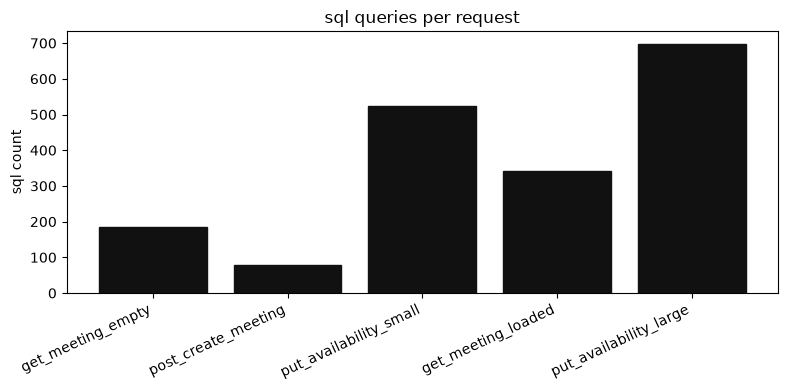

In [32]:
sql_n = [r["sql_n"] for r in rows]

plt.figure(figsize=(8, 4))
plt.bar(names, sql_n, color=BLACK, edgecolor=BLACK)
plt.ylabel("sql count")
plt.xticks(rotation=25, ha="right")
plt.title("sql queries per request")
plt.tight_layout()
plt.show()

**Plot 3 — SQL statements per request**

Counts every SQLite statement during one handler (ORM flushes, deletes, inserts — from hooks in `backend/tests/conftest.py`). **Taller bar = more database chatter**, even when latency (Plot 1) stays low.

- High count on **GET** means the read path does more ORM work than a single query would suggest.
- **PUT** bars grow with slot count (delete old slots + insert new ones per save).

**Takeaway for reviewers:** latency here is still milliseconds on a laptop; the interesting finding is **statement amplification** — a reason to consider bulk SQL or fewer round-trips later. These tests use **one client, one request at a time**, not concurrent load.